# 02 – Contract value model

**Goal:** learn what the market pays for on-field production, so that in Phase 4 we can compare each player's
*actual* pay with the pay his production would normally earn.

**Target:** `apy_cap_pct`, the contract's average per year as a share of the salary cap when it was signed.

### Choices and why
- **Veteran contracts only.** Rookie-scale pay is fixed by draft slot, not negotiated on performance. Training on
  rookie deals would teach the model that great production can cost 1% of the cap, which is a rule of the CBA,
  not a market price. We train on the market, then later apply it to everyone.
- **Time-based split: train 2019–2023, test 2024–2025.** The model will be used on seasons it hasn't seen, so it's
  tested that way. A random split would put a player's 2022 and 2023 seasons (similar stats, same contract)
  on both sides, and the score would look better than it really is.
- **Baselines first.** A score only means something next to a simple alternative. We start with "predict the
  position average", then a linear regression, and XGBoost has to beat both.
- **Position as a feature (one-hot).** The EDA showed EPA isn't comparable across positions (RB median EPA/play
  is negative, WR's is +0.22), and the market pays QBs on a different scale entirely.
- **Tuning with season-based CV on training seasons only.** The test seasons are touched exactly once, at the end.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))   # so `src` imports work from notebooks/

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import shap
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

from src.model import POSITIONS, TARGET, build_features, evaluate, load_player_season, season_cv_splits

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 4)

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.axisbelow": True,
})

## 1. Data and split

In [2]:
ps = load_player_season()
vets = ps[~ps["is_rookie_contract"]].reset_index(drop=True)

TRAIN_SEASONS, TEST_SEASONS = range(2019, 2024), range(2024, 2026)
train = vets[vets["season"].isin(TRAIN_SEASONS)].reset_index(drop=True)
test = vets[vets["season"].isin(TEST_SEASONS)].reset_index(drop=True)

print(f"all player-seasons: {len(ps):,}  ->  veteran contracts: {len(vets):,}")
print(f"train (2019–2023): {len(train):,} rows   test (2024–2025): {len(test):,} rows")
pd.crosstab(vets["position"], np.where(vets["season"] <= 2023, "train", "test")).loc[POSITIONS, ["train", "test"]]

all player-seasons: 2,402  ->  veteran contracts: 1,438
train (2019–2023): 1,025 rows   test (2024–2025): 413 rows


col_0,train,test
position,,
QB,146,63
RB,202,86
WR,423,163
TE,254,101


### Leakage check: the same contract on both sides of the split

A multi-year contract appears once per season. Mahomes's 2020 contract is his target in 2020–2025, so
his 2023 row (train) and 2024 row (test) share the exact same answer. The model never sees player names, but
it is partly being graded on contract values it has already fit. We flag those rows and also report a
stricter score on **unseen contracts** only.

In [3]:
train_contracts = set(zip(train["gsis_id"], train["contract_year_signed"]))
test["contract_seen_in_train"] = [(g, y) in train_contracts for g, y in zip(test["gsis_id"], test["contract_year_signed"])]
print(f"test rows whose contract also appears in training: {test['contract_seen_in_train'].sum()} of {len(test)} "
      f"({test['contract_seen_in_train'].mean():.0%})")

test rows whose contract also appears in training: 70 of 413 (17%)


In [4]:
X_train, X_test = build_features(train), build_features(test)
X_train_lin, X_test_lin = build_features(train, drop_first=True), build_features(test, drop_first=True)
y_train, y_test = train[TARGET], test[TARGET]

# CV folds inside the training seasons: 2019–20 -> 2021, 2019–21 -> 2022, 2019–22 -> 2023
cv_folds = season_cv_splits(train["season"], first_val_season=2021)
for i, (tr, va) in enumerate(cv_folds, 1):
    print(f"fold {i}: train seasons {sorted(train.loc[tr, 'season'].unique())}  ->  validate {train.loc[va, 'season'].unique()}")
print("\nfeatures:", list(X_train.columns))

fold 1: train seasons [np.int32(2019), np.int32(2020)]  ->  validate [2021]
fold 2: train seasons [np.int32(2019), np.int32(2020), np.int32(2021)]  ->  validate [2022]
fold 3: train seasons [np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022)]  ->  validate [2023]

features: ['position_QB', 'position_RB', 'position_WR', 'position_TE', 'age', 'games_played', 'offense_snaps', 'snap_pct', 'dropbacks', 'rushes', 'targets', 'receptions', 'total_epa', 'epa_per_play', 'success_rate', 'cpoe', 'target_share', 'air_yards_share', 'air_yards', 'yards_after_catch']


## 2. Baseline 0: predict the position average

The dumbest reasonable model: every QB gets the average QB cap %, and so on. It tells us how much of the
score comes from position alone.

In [5]:
pos_mean = train.groupby("position")[TARGET].mean()
pred_posavg = test["position"].map(pos_mean).to_numpy()
res_posavg = evaluate(y_test, pred_posavg, test["position"])
res_posavg

,n,R2,MAE_pct_of_cap
group,,,
all,413,0.3422,3.6089
QB,63,-0.0424,8.8742
RB,86,-0.0407,1.5584
WR,163,-0.0184,3.7734
TE,101,-0.0003,1.8050


## 3. Baseline 1: linear regression

Standardize the features, then fit ordinary least squares. It can only learn straight-line effects, and the
position dummies only shift the intercept: it can't learn that EPA is worth more for a QB than for a RB.

In [6]:
linear = make_pipeline(StandardScaler(), LinearRegression())

cv_mae_lin = -cross_val_score(linear, X_train_lin, y_train, cv=cv_folds, scoring="neg_mean_absolute_error")
linear.fit(X_train_lin, y_train)
pred_lin = linear.predict(X_test_lin)

print("season-CV MAE per fold (pp of cap):", (100 * cv_mae_lin).round(3), " mean:", round(100 * cv_mae_lin.mean(), 3))
res_lin = evaluate(y_test, pred_lin, test["position"])
res_lin

season-CV MAE per fold (pp of cap): [1.765 2.387 2.31 ]  mean: 2.154


,n,R2,MAE_pct_of_cap
group,,,
all,413,0.6473,2.3156
QB,63,0.3387,6.4390
RB,86,0.3479,1.1258
WR,163,0.6236,2.1181
TE,101,0.5371,1.0756


## 4. XGBoost, tuned with season-based CV

Gradient-boosted trees can learn non-linear effects (pay rising steeply at the top) and interactions
(EPA matters differently by position, production matters differently by age). We tune a small grid,
scored by MAE on the three season folds. The test seasons are never used here.

In [7]:
param_grid = {
    "max_depth": [2, 3, 4],             # how many splits deep each tree goes (interaction depth)
    "learning_rate": [0.03, 0.1],       # how much each new tree corrects the previous ones
    "n_estimators": [200, 500],         # number of trees
    "min_child_weight": [1, 5],         # minimum data in a leaf: higher = smoother, less overfitting
}
xgb_base = XGBRegressor(objective="reg:squarederror", subsample=0.8, colsample_bytree=0.8,
                        random_state=42, n_jobs=4)

search = GridSearchCV(xgb_base, param_grid, cv=cv_folds, scoring="neg_mean_absolute_error",
                      return_train_score=True)
search.fit(X_train, y_train)

cv_table = (pd.DataFrame(search.cv_results_)
            .assign(cv_MAE=lambda d: -100 * d["mean_test_score"], train_MAE=lambda d: -100 * d["mean_train_score"])
            .sort_values("cv_MAE")[["params", "cv_MAE", "train_MAE"]])
print("best params:", search.best_params_)
cv_table.head(8)

best params: {'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 500}


,params,cv_MAE,train_MAE
11,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c...",1.9257,0.6158
9,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c...",1.9310,0.5178
10,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c...",1.9394,0.9976
20,"{'learning_rate': 0.1, 'max_depth': 4, 'min_ch...",1.9491,0.3929
8,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c...",1.9576,0.9134
7,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c...",1.9658,0.8824
21,"{'learning_rate': 0.1, 'max_depth': 4, 'min_ch...",1.9678,0.0981
5,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c...",1.9694,0.8228


**Grid-boundary check.** The best settings sit at the edge of the grid (deepest trees, most trees),
so maybe a bigger model would do better. Extend the grid past the edge and compare CV error.

In [8]:
wider = GridSearchCV(xgb_base, {"max_depth": [4, 5, 6], "learning_rate": [0.03], "n_estimators": [500, 1000],
                                 "min_child_weight": [5, 10]},
                     cv=cv_folds, scoring="neg_mean_absolute_error").fit(X_train, y_train)
print(f"original grid best CV MAE: {-100 * search.best_score_:.3f} pp  {search.best_params_}")
print(f"wider grid best CV MAE:    {-100 * wider.best_score_:.3f} pp  {wider.best_params_}")
print("-> difference is negligible, so we keep the simpler original model (max_depth 4).")

original grid best CV MAE: 1.926 pp  {'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 500}
wider grid best CV MAE:    1.918 pp  {'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 5, 'n_estimators': 500}
-> difference is negligible, so we keep the simpler original model (max_depth 4).


In [9]:
xgb = search.best_estimator_      # refit on all of 2019–2023 with the best params
pred_xgb = xgb.predict(X_test)
res_xgb = evaluate(y_test, pred_xgb, test["position"])
res_xgb

,n,R2,MAE_pct_of_cap
group,,,
all,413,0.6744,2.0658
QB,63,0.3661,5.7122
RB,86,0.3594,1.0815
WR,163,0.7053,1.7557
TE,101,0.5071,1.1301


## 5. Test-set results (2024–2025, veteran contracts)

In [10]:
comparison = pd.concat({
    "position average": res_posavg, "linear regression": res_lin, "XGBoost": res_xgb,
}, axis=1).round(3)
comparison

position average                       linear regression                       XGBoost                      
                     n     R2 MAE_pct_of_cap                 n     R2 MAE_pct_of_cap       n     R2 MAE_pct_of_cap
group                                                                                                             
all                413  0.342          3.609               413  0.647          2.316     413  0.674          2.066
QB                  63 -0.042          8.874                63  0.339          6.439      63  0.366          5.712
RB                  86 -0.041          1.558                86  0.348          1.126      86  0.359          1.081
WR                 163 -0.018          3.773               163  0.624          2.118     163  0.705          1.756
TE                 101 -0.000          1.805               101  0.537          1.076     101  0.507          1.130

### Overfitting check: train vs. CV vs. test error

If training error is far below CV/test error, the model memorized the training rows. CV and test should be
similar if the CV scheme mimics the real test.

In [11]:
fit_check = pd.DataFrame({
    "train MAE": [100 * mean_absolute_error(y_train, linear.predict(X_train_lin)),
                  100 * mean_absolute_error(y_train, xgb.predict(X_train))],
    "season-CV MAE": [100 * cv_mae_lin.mean(), -100 * search.best_score_],
    "test MAE": [res_lin.loc["all", "MAE_pct_of_cap"], res_xgb.loc["all", "MAE_pct_of_cap"]],
}, index=["linear regression", "XGBoost"]).round(3)
fit_check

,train MAE,season-CV MAE,test MAE
linear regression,1.982,2.154,2.316
XGBoost,0.854,1.926,2.066


### Stricter test: only contracts the model has never seen

Removes the test rows whose contract already appeared in training (see the leakage check).

In [12]:
unseen = ~test["contract_seen_in_train"].to_numpy()
strict = pd.concat({
    "linear regression": evaluate(y_test[unseen], pred_lin[unseen], test.loc[unseen, "position"]),
    "XGBoost": evaluate(y_test[unseen], pred_xgb[unseen], test.loc[unseen, "position"]),
}, axis=1).round(3)
strict

linear regression                       XGBoost                      
                      n     R2 MAE_pct_of_cap       n     R2 MAE_pct_of_cap
group                                                                      
all                 343  0.614          2.016     343  0.621          1.850
QB                   45  0.381          5.680      45  0.354          5.222
RB                   78  0.318          1.093      78  0.275          1.107
WR                  141  0.651          1.971     141  0.714          1.659
TE                   79  0.421          0.920      79  0.409          1.001

### What does the MAE mean in dollars?

MAE is in percentage points of the cap. To convert, we need the cap itself, which we back out of the data:
cap = APY / (APY as % of cap), median over contracts signed that year.

In [13]:
with duckdb.connect(str(ROOT / "data" / "nfl.duckdb"), read_only=True) as con:
    implied_cap = con.sql("""
        SELECT year_signed AS year, median(apy / apy_cap_pct) AS cap_musd
        FROM contracts
        WHERE apy_cap_pct >= 0.05 AND year_signed BETWEEN 2024 AND 2025   -- bigger deals: less rounding error
        GROUP BY 1 ORDER BY 1""").df().set_index("year")["cap_musd"]

dollars = pd.DataFrame({
    "implied cap ($M)": implied_cap.round(1),
    "linear MAE ($M)": (implied_cap * res_lin.loc["all", "MAE_pct_of_cap"] / 100).round(2),
    "XGBoost MAE ($M)": (implied_cap * res_xgb.loc["all", "MAE_pct_of_cap"] / 100).round(2),
})
dollars

,implied cap ($M),linear MAE ($M),XGBoost MAE ($M)
year,,,
2024,255.4,5.91,5.28
2025,278.8,6.46,5.76


### Where does the model miss?

Average actual vs. predicted pay, grouped by how much the player is actually paid.

In [14]:
bands = pd.cut(y_test, [0, .02, .05, .10, .15, .30], labels=["<2%", "2–5%", "5–10%", "10–15%", "15%+"])
(pd.DataFrame({"actual": y_test, "predicted": pred_xgb, "band": bands})
   .groupby("band", observed=True)
   .agg(n=("actual", "size"), mean_actual_pct=("actual", "mean"), mean_predicted_pct=("predicted", "mean"))
   .assign(mean_actual_pct=lambda d: 100 * d["mean_actual_pct"], mean_predicted_pct=lambda d: 100 * d["mean_predicted_pct"])
   .round(2))

,n,mean_actual_pct,mean_predicted_pct
band,,,
<2%,208,0.82,1.98
2–5%,88,3.46,3.97
5–10%,53,7.35,6.03
10–15%,33,12.03,9.66
15%+,31,21.46,14.73


In [15]:
# QBs: the five biggest under- and over-predictions
qb = test[test["position"] == "QB"].assign(predicted=pred_xgb[(test["position"] == "QB").to_numpy()])
qb = qb.assign(error=qb["predicted"] - qb[TARGET]).sort_values("error")
cols = ["player_name", "season", "team", "games_played", "dropbacks", "total_epa", TARGET, "predicted"]
pd.concat([qb.head(5), qb.tail(5)])[cols].round(3)

,player_name,season,team,games_played,dropbacks,total_epa,apy_cap_pct,predicted
16,Joe Burrow,2025,CIN,8,284,33.022,0.245,0.077
229,Trevor Lawrence,2024,JAX,10,314,4.658,0.215,0.070
101,Deshaun Watson,2024,CLE,7,270,-64.439,0.221,0.078
39,Lamar Jackson,2025,BAL,13,366,30.202,0.231,0.095
141,Dak Prescott,2024,DAL,8,311,-12.875,0.235,0.111
1,Aaron Rodgers,2025,PIT,16,536,18.543,0.049,0.150
293,Carson Wentz,2025,MIN,5,196,5.836,0.005,0.107
40,Sam Darnold,2024,MIN,17,620,42.062,0.039,0.150
237,Russell Wilson,2024,PIT,11,387,-2.035,0.005,0.179
375,Daniel Jones,2024,NYG,10,381,-14.986,0.004,0.184


## 6. Predicted vs. actual (XGBoost, test set)

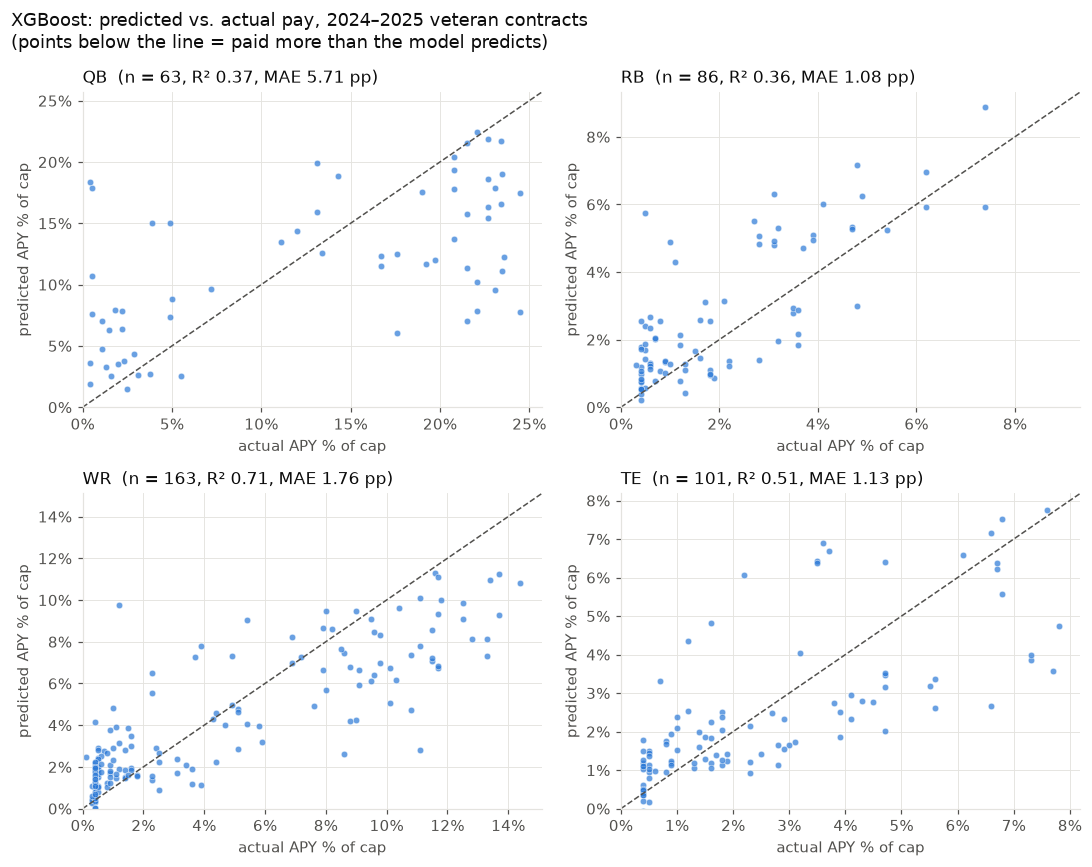

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, pos in zip(axes.flat, POSITIONS):
    m = (test["position"] == pos).to_numpy()
    actual, pred = y_test[m], pred_xgb[m]
    lim = max(actual.max(), pred.max()) * 1.05
    ax.plot([0, lim], [0, lim], color=MUTED, linewidth=1, linestyle="--")  # perfect-prediction line
    ax.scatter(actual, pred, s=18, color=BLUE, alpha=0.7, edgecolors="white", linewidths=0.4)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    r = res_xgb.loc[pos]
    ax.set_title(f"{pos}  (n = {int(r['n'])}, R² {r['R2']:.2f}, MAE {r['MAE_pct_of_cap']:.2f} pp)", loc="left", fontsize=11)
    ax.set_xlabel("actual APY % of cap"); ax.set_ylabel("predicted APY % of cap")
fig.suptitle("XGBoost: predicted vs. actual pay, 2024–2025 veteran contracts\n(points below the line = paid more than the model predicts)",
             x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "pred_vs_actual.png")
plt.show()

## 7. SHAP: why the model predicts what it does

SHAP splits each prediction into contributions from each feature, starting from the average prediction
(the "base value"). Contributions add up exactly to the prediction. Values are shown in percentage points of cap.

base value (average prediction): 4.15% of cap


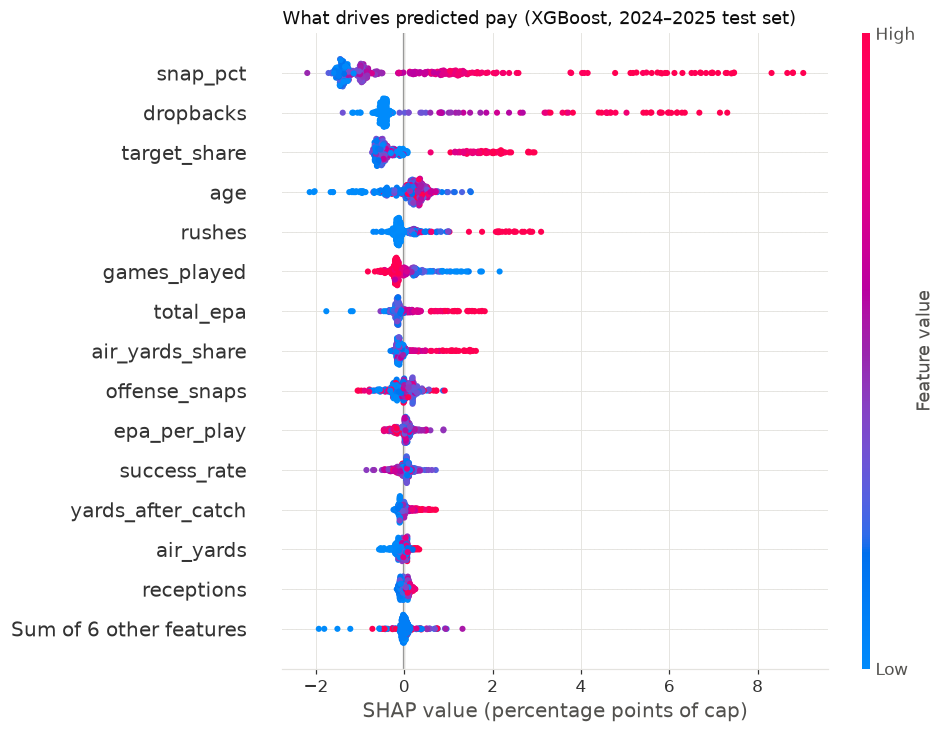

In [17]:
explainer = shap.TreeExplainer(xgb)
sv = explainer(X_test)
# Rescale from fraction of cap to percentage points so the plots read in % of cap.
sv_pp = shap.Explanation(values=sv.values * 100, base_values=sv.base_values * 100,
                         data=X_test.to_numpy(), feature_names=list(X_test.columns))
print(f"base value (average prediction): {sv_pp.base_values[0]:.2f}% of cap")

plt.figure()
shap.plots.beeswarm(sv_pp, max_display=15, show=False)
plt.gca().set_xlabel("SHAP value (percentage points of cap)")
plt.title("What drives predicted pay (XGBoost, 2024–2025 test set)", loc="left", fontsize=12)
plt.savefig(FIG_DIR / "shap_summary.png")
plt.show()

In [18]:
# Global importance: average absolute SHAP value per feature.
importance = pd.Series(np.abs(sv_pp.values).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
importance.round(3).head(12).to_frame("mean |SHAP| (pp of cap)")

,mean |SHAP| (pp of cap)
snap_pct,1.608
dropbacks,0.899
target_share,0.700
age,0.361
rushes,0.311
games_played,0.254
total_epa,0.250
air_yards_share,0.201
offense_snaps,0.193
epa_per_play,0.123


### Waterfalls for three well-known 2024 seasons

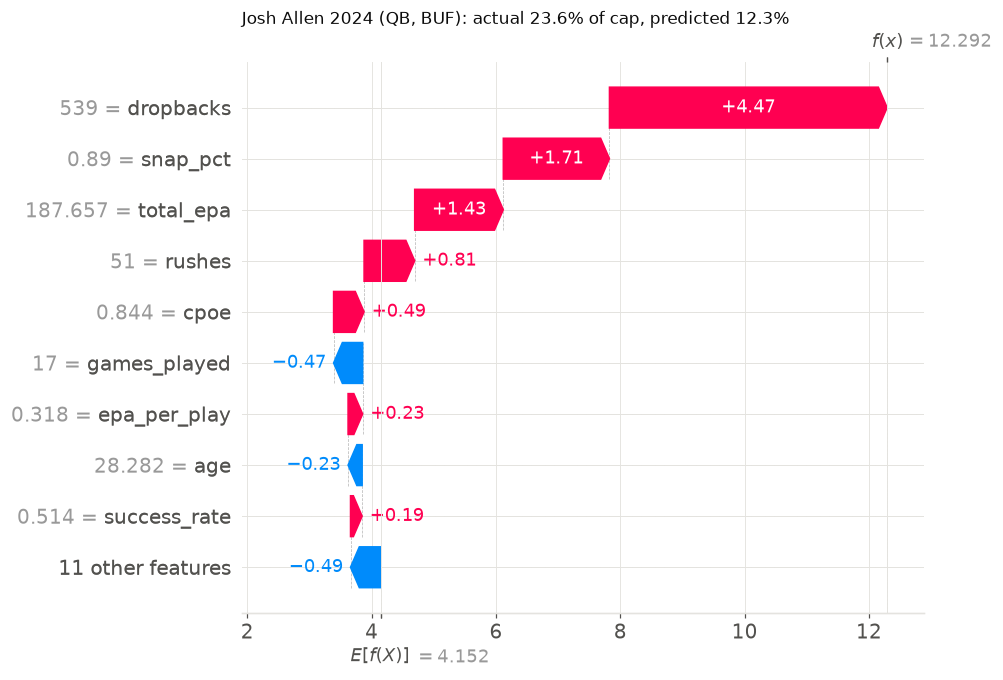

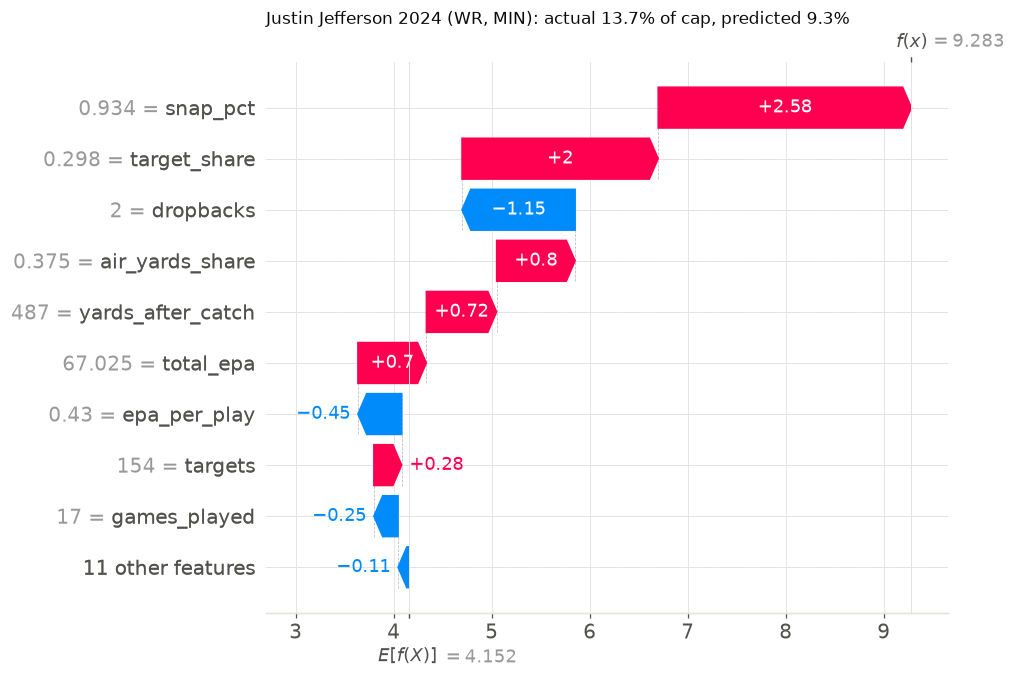

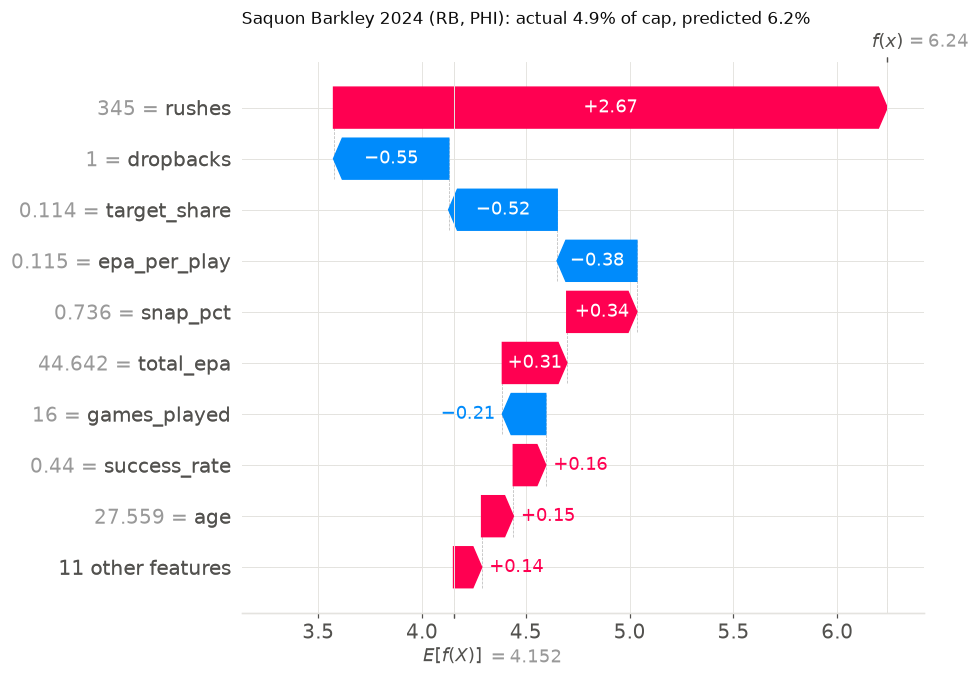

In [19]:
examples = [("Josh Allen", 2024), ("Justin Jefferson", 2024), ("Saquon Barkley", 2024)]

for name, season in examples:
    i = test.index[(test["player_name"] == name) & (test["season"] == season)][0]
    row = test.loc[i]
    plt.figure()
    shap.plots.waterfall(sv_pp[i], max_display=10, show=False)
    plt.title(f"{name} {season} ({row['position']}, {row['team']}): actual {100 * row[TARGET]:.1f}% of cap, "
              f"predicted {pred_xgb[i] * 100:.1f}%", loc="left", fontsize=11)
    slug = name.lower().replace(" ", "_").replace(".", "")
    plt.savefig(FIG_DIR / f"shap_waterfall_{slug}_{season}.png")
    plt.show()

## Observations

Every number below is printed by a cell above.

**Performance (test seasons 2024–2025, 413 veteran player-seasons)**
1. **XGBoost beats both baselines.** R² 0.674 / MAE 2.07 pp of cap, vs. linear regression 0.647 / 2.32 pp and
   position-average 0.342 / 3.61 pp. At the 2024 cap ($255.4M implied) the XGBoost MAE is about **$5.3M**
   (linear: $5.9M).
2. **The gain over linear regression is real but modest.** XGBoost wins at QB, RB and WR; linear is slightly
   better at TE (R² 0.537 vs 0.507).
3. **Overall R² is flattered by position.** Knowing only the position already gives R² 0.34, because QBs are paid on
   a different scale. Within a position, XGBoost explains 36–71% of the variation (QB 0.37, RB 0.36, TE 0.51, WR 0.71).
4. **QB is the hardest position** (MAE 5.71 pp, about $14.6M). The biggest under-predictions are injured stars
   (Burrow 2025: 8 games; Watson 2024: 7; Prescott 2024: 8) whose production that season was low. The biggest
   over-predictions are cheap veterans who started (e.g. Darnold 2024: paid 3.9%, predicted 15.0%).

**Overfitting**
5. **XGBoost fits its training rows much more tightly than new data** (train MAE 0.85 vs season-CV 1.93 vs
   test 2.07). Part of the reason is that a multi-year contract repeats across a player's seasons, so the
   trees can nearly memorize it. What matters is that **CV and test agree**, so the CV score was an honest
   estimate and the test score is a fair measure of generalization. Linear regression barely overfits (1.98 / 2.15 / 2.32) but underfits.
6. **The tuned settings landed on the grid edge**, but widening the grid improved CV MAE by under 0.01 pp, so the
   simpler model stands.

**Leakage**
7. **No feature contains the target.** Contract columns (APY, years, signing year, type) are excluded.
8. **The same contract on both sides of the split:** 70 of 413 test rows (17%) carry a contract the model also saw
   in training. On the 343 unseen contracts only, XGBoost gets R² 0.621 / MAE 1.85 pp and linear 0.614 / 2.02 pp.
   The ranking holds, and the stricter number is the one to quote.
9. **Data limitation found:** a contract signed in the same year as the season, by a team the player didn't play for
   that season, is sometimes selected (29 rows, 1.2%; nearly all minimum deals). The one material case is
   **Daniel Jones 2024**: target 0.4% (the Vikings deal after his release) instead of his 17.8% Giants contract.

**Regression toward the mean (important for Phase 4)**
10. The model **compresses the extremes**: contracts under 2% of cap average 0.82% actual vs 1.98% predicted; contracts
    15%+ average 21.46% actual vs 14.73% predicted. Elite contracts will tend to look "overpaid" and minimum deals
    "underpaid" partly by construction. Phase 4 must account for this (e.g. compare players within pay tiers, or
    rank residuals within position).

**SHAP: what drives predicted pay**
11. **Role and volume dominate:** snap % (mean |SHAP| 1.61 pp), dropbacks (0.90; effectively "is a starting QB"),
    target share (0.70), age (0.36), rushes (0.31). Efficiency matters far less (EPA/play 0.12, success rate 0.12).
    The market pays for being a high-usage starter more than for per-play efficiency.
12. **Position dummies aren't top features** because dropbacks, rushes and targets already reveal the position.
13. **Caveats:** SHAP explains the *model*, not causation. Snap % and target share are partly a *result* of pay
    (teams play the player they paid). And very high EPA/play slightly *lowers* predicted pay (Jefferson 2024: −0.45 pp),
    because the training data's highest per-play rates come from low-volume depth players. This is the
    small-sample noise flagged in the EDA.